In [ ]:
import pandas as pd #AP24110011603
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
from google.colab import files

uploaded = files.upload()

# Read the uploaded CSV file
df = pd.read_csv(next(iter(uploaded)))

# Display the first 5 rows
print(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns)
print("\nMissing Values:\n", df.isnull().sum())

Saving WineQT.csv to WineQT.csv
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1 

In [ ]:
df = pd.read_csv(next(iter(uploaded)), sep=';')

In [ ]:
# Re-read the dataframe with the correct comma separator
df = pd.read_csv(next(iter(uploaded)), sep=',')

# Separate input features and target variable
X = df.drop('quality', axis=1)
y = df['quality']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (1143, 12)
Target shape: (1143,)


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (1143, 12)


In [ ]:
# Apply PCA
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original data shape:", X_scaled.shape)
print("PCA-transformed data shape:", X_pca.shape)

# Display explained variance ratio
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

# Display cumulative explained variance
print("\nCumulative Explained Variance:")
print(np.cumsum(pca.explained_variance_ratio_))

Original data shape: (1143, 12)
PCA-transformed data shape: (1143, 12)

Explained Variance Ratio:
[0.27194409 0.15872089 0.13585374 0.10096166 0.08046427 0.07449103
 0.05187962 0.04467196 0.03480083 0.02701673 0.01435664 0.00483854]

Cumulative Explained Variance:
[0.27194409 0.43066498 0.56651872 0.66748038 0.74794465 0.82243568
 0.8743153  0.91898726 0.9537881  0.98080482 0.99516146 1.        ]


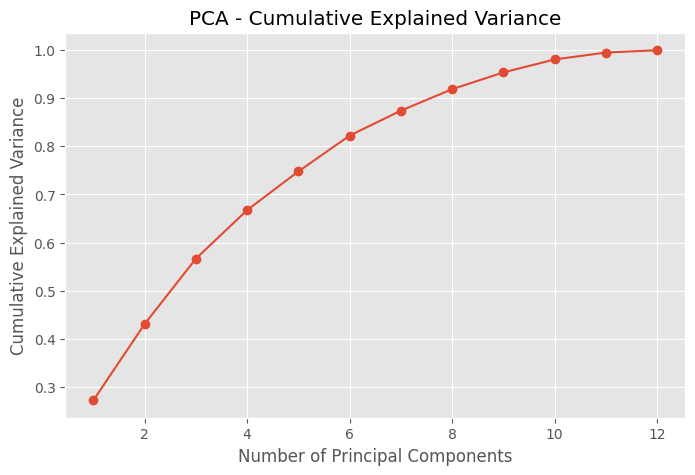

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')
plt.grid(True)

plt.show()

In [ ]:
# Apply PCA with 2 components
pca_2 = PCA(n_components=2)

X_pca_2 = pca_2.fit_transform(X_scaled)

# Create a new DataFrame
pca_df = pd.DataFrame(
    X_pca_2,
    columns=['PC1', 'PC2']
)

# Add the wine quality target
pca_df['quality'] = y.to_numpy()

print(pca_df.head())

print("\nExplained variance by PC1 and PC2:")
print(pca_2.explained_variance_ratio_)

print(
    "\nTotal variance explained:",
    round(pca_2.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

        PC1       PC2  quality
0 -1.078814  1.033899        5
1 -0.307332  2.289875        5
2 -0.265776  1.348870        5
3  2.617729 -0.099643        6
4 -1.080670  1.032473        5

Explained variance by PC1 and PC2:
[0.27194409 0.15872089]

Total variance explained: 43.07 %


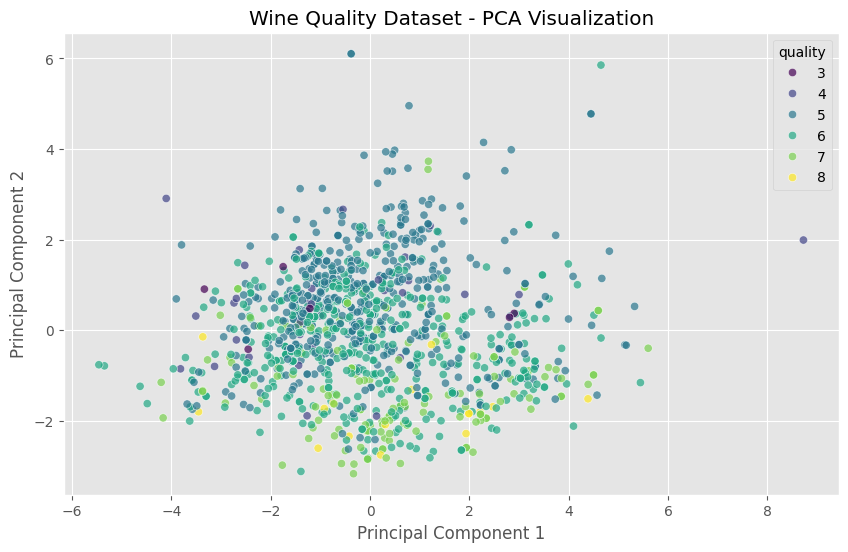

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='quality',
    palette='viridis',
    alpha=0.7
)

plt.title('Wine Quality Dataset - PCA Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

In [ ]:
pca_95 = PCA(n_components=0.95)

X_pca_95 = pca_95.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Reduced number of features:", X_pca_95.shape[1])

print(
    "Total variance retained:",
    round(pca_95.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original number of features: 12
Reduced number of features: 9
Total variance retained: 95.38 %


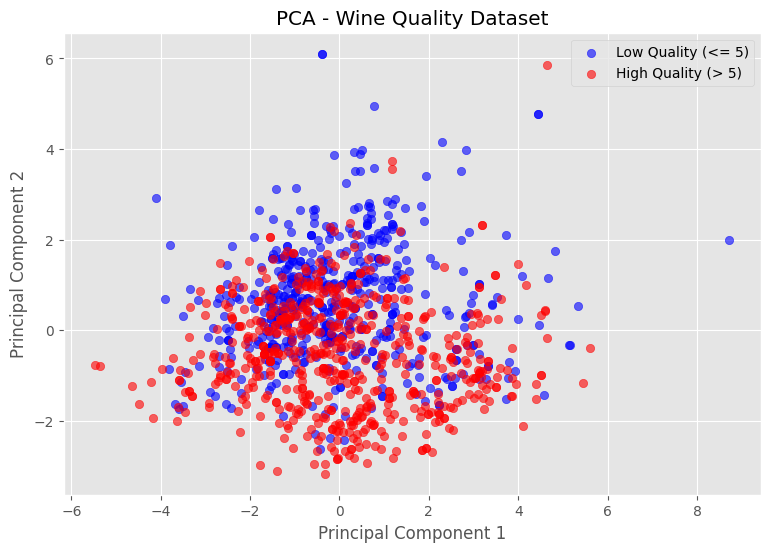

Variance explained by PC1 and PC2: 43.07 %


In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop('quality', axis=1)
y = df['quality']

# Standardize the features
X_scaled = StandardScaler().fit_transform(X)

# Apply PCA with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Divide wine quality into two groups
# Quality <= 5: Low Quality
# Quality > 5: High Quality
low_quality = y <= 5
high_quality = y > 5

# Plot using exactly two colours
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[low_quality, 0],
    X_pca[low_quality, 1],
    color='blue',
    label='Low Quality (<= 5)',
    alpha=0.6
)

plt.scatter(
    X_pca[high_quality, 0],
    X_pca[high_quality, 1],
    color='red',
    label='High Quality (> 5)',
    alpha=0.6
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - Wine Quality Dataset')
plt.legend()
plt.grid(True)
plt.show()

# Display explained variance
print("Variance explained by PC1 and PC2:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")